In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/muratkokludataset/dry-bean-dataset/Dry_Bean_Dataset/Dry_Bean_Dataset.arff
/kaggle/input/datasets/muratkokludataset/dry-bean-dataset/Dry_Bean_Dataset/Dry_Bean_Dataset.xlsx
/kaggle/input/datasets/muratkokludataset/dry-bean-dataset/Dry_Bean_Dataset/Dry_Bean_Dataset_Citation_Request.txt


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.io import arff

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

In [3]:
file_path = '/kaggle/input/datasets/muratkokludataset/dry-bean-dataset/Dry_Bean_Dataset/Dry_Bean_Dataset.arff'

data, meta = arff.loadarff(file_path)

df = pd.DataFrame(data)

for col in df.select_dtypes(include=['object']).columns:
    df[col] = df[col].str.decode('utf-8')

print(df.head())

      Area  Perimeter  MajorAxisLength  MinorAxisLength  AspectRation  \
0  28395.0    610.291       208.178117       173.888747      1.197191   
1  28734.0    638.018       200.524796       182.734419      1.097356   
2  29380.0    624.110       212.826130       175.931143      1.209713   
3  30008.0    645.884       210.557999       182.516516      1.153638   
4  30140.0    620.134       201.847882       190.279279      1.060798   

   Eccentricity  ConvexArea  EquivDiameter    Extent  Solidity  roundness  \
0      0.549812     28715.0     190.141097  0.763923  0.988856   0.958027   
1      0.411785     29172.0     191.272750  0.783968  0.984986   0.887034   
2      0.562727     29690.0     193.410904  0.778113  0.989559   0.947849   
3      0.498616     30724.0     195.467062  0.782681  0.976696   0.903936   
4      0.333680     30417.0     195.896503  0.773098  0.990893   0.984877   

   Compactness  ShapeFactor1  ShapeFactor2  ShapeFactor3  ShapeFactor4  Class  
0     0.913358    

In [4]:
print("Dataset Shape:", df.shape)

print("\nDataset Information:")
print(df.info())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nClass Distribution:")
print(df['Class'].value_counts())

Dataset Shape: (13611, 17)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13611 entries, 0 to 13610
Data columns (total 17 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Area             13611 non-null  float64
 1   Perimeter        13611 non-null  float64
 2   MajorAxisLength  13611 non-null  float64
 3   MinorAxisLength  13611 non-null  float64
 4   AspectRation     13611 non-null  float64
 5   Eccentricity     13611 non-null  float64
 6   ConvexArea       13611 non-null  float64
 7   EquivDiameter    13611 non-null  float64
 8   Extent           13611 non-null  float64
 9   Solidity         13611 non-null  float64
 10  roundness        13611 non-null  float64
 11  Compactness      13611 non-null  float64
 12  ShapeFactor1     13611 non-null  float64
 13  ShapeFactor2     13611 non-null  float64
 14  ShapeFactor3     13611 non-null  float64
 15  ShapeFactor4     13611 non-null  float64
 16  Class    

In [5]:
X = df.drop('Class', axis=1).values
y = df['Class'].values

label_encoder = LabelEncoder()
y = label_encoder.fit_transform(y)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

num_classes = len(np.unique(y_train))

Y_train = np.eye(num_classes)[y_train]
Y_test = np.eye(num_classes)[y_test]

print("Training Shape:", X_train.shape)
print("Testing Shape:", X_test.shape)
print("Number of Classes:", num_classes)

Training Shape: (10888, 16)
Testing Shape: (2723, 16)
Number of Classes: 7


In [6]:
def softmax(z):
    z = z - np.max(z, axis=1, keepdims=True)
    exp_z = np.exp(z)
    return exp_z / np.sum(exp_z, axis=1, keepdims=True)


def compute_loss(Y_true, Y_pred):
    epsilon = 1e-15
    Y_pred = np.clip(Y_pred, epsilon, 1 - epsilon)

    loss = -np.mean(
        np.sum(Y_true * np.log(Y_pred), axis=1)
    )

    return loss

In [7]:
np.random.seed(42)

n_samples, n_features = X_train.shape

W = np.random.randn(n_features, num_classes) * 0.01
b = np.zeros((1, num_classes))

learning_rate = 0.01
epochs = 200
batch_size = 64
beta = 0.9

vW = np.zeros_like(W)
vb = np.zeros_like(b)

loss_history = []

In [8]:
for epoch in range(epochs):

    indices = np.random.permutation(n_samples)

    X_shuffled = X_train[indices]
    Y_shuffled = Y_train[indices]

    for start in range(0, n_samples, batch_size):

        end = start + batch_size

        X_batch = X_shuffled[start:end]
        Y_batch = Y_shuffled[start:end]

        m = len(X_batch)

        # Forward Propagation
        z = np.dot(X_batch, W) + b
        y_pred = softmax(z)

        # Calculate Error
        error = y_pred - Y_batch

        # Calculate Gradients
        dW = np.dot(X_batch.T, error) / m
        db = np.sum(error, axis=0, keepdims=True) / m

        # Momentum Update
        vW = beta * vW + dW
        vb = beta * vb + db

        # Update Parameters
        W = W - learning_rate * vW
        b = b - learning_rate * vb

    # Calculate Loss After Each Epoch
    z_all = np.dot(X_train, W) + b
    y_all_pred = softmax(z_all)

    loss = compute_loss(Y_train, y_all_pred)

    loss_history.append(loss)

    if (epoch + 1) % 20 == 0:
        print(f"Epoch {epoch + 1}, Loss: {loss:.4f}")

Epoch 20, Loss: 0.2254
Epoch 40, Loss: 0.2176
Epoch 60, Loss: 0.2149
Epoch 80, Loss: 0.2134
Epoch 100, Loss: 0.2127
Epoch 120, Loss: 0.2120
Epoch 140, Loss: 0.2117
Epoch 160, Loss: 0.2114
Epoch 180, Loss: 0.2112
Epoch 200, Loss: 0.2109


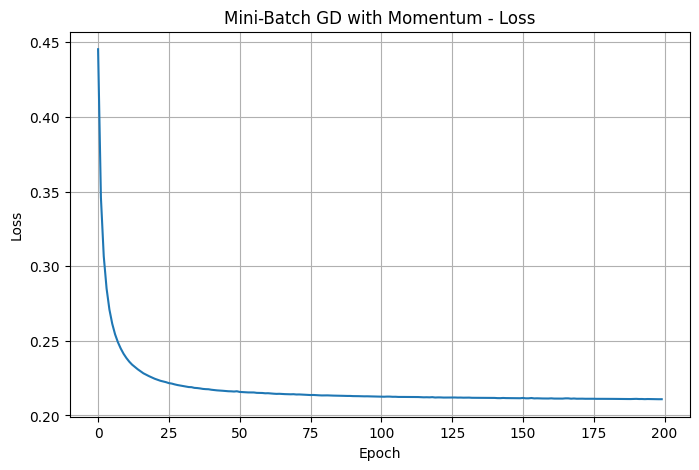

In [9]:
plt.figure(figsize=(8, 5))

plt.plot(loss_history)

plt.title('Mini-Batch GD with Momentum - Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')

plt.grid(True)
plt.show()

In [10]:
z_test = np.dot(X_test, W) + b

y_test_pred = softmax(z_test)

y_pred_classes = np.argmax(y_test_pred, axis=1)

y_true_classes = y_test

In [11]:
accuracy = accuracy_score(y_true_classes, y_pred_classes)

precision = precision_score(
    y_true_classes,
    y_pred_classes,
    average='macro'
)

recall = recall_score(
    y_true_classes,
    y_pred_classes,
    average='macro'
)

f1 = f1_score(
    y_true_classes,
    y_pred_classes,
    average='macro'
)

print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1 Score:", f1)

Accuracy: 0.9203084832904884
Precision: 0.9343616520759078
Recall: 0.9316136819409689
F1 Score: 0.9327229071069884


In [12]:
print(classification_report(
    y_true_classes,
    y_pred_classes,
    target_names=label_encoder.classes_
))

              precision    recall  f1-score   support

    BARBUNYA       0.95      0.89      0.92       265
      BOMBAY       1.00      1.00      1.00       104
        CALI       0.93      0.94      0.93       326
    DERMASON       0.93      0.90      0.91       709
       HOROZ       0.96      0.95      0.96       386
       SEKER       0.93      0.95      0.94       406
        SIRA       0.84      0.88      0.86       527

    accuracy                           0.92      2723
   macro avg       0.93      0.93      0.93      2723
weighted avg       0.92      0.92      0.92      2723



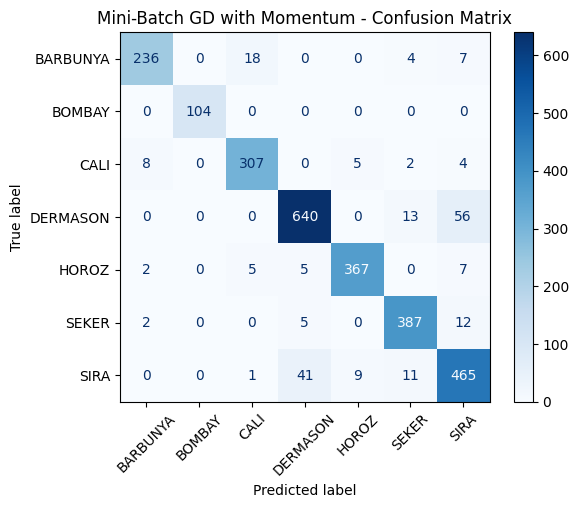

In [13]:
cm = confusion_matrix(
    y_true_classes,
    y_pred_classes
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=label_encoder.classes_
)

disp.plot(cmap='Blues', xticks_rotation=45)

plt.title('Mini-Batch GD with Momentum - Confusion Matrix')
plt.show()

In [14]:
minibatch_results = {
    'Accuracy': accuracy,
    'Precision': precision,
    'Recall': recall,
    'F1 Score': f1,
    'Loss History': loss_history
}

print(minibatch_results)

{'Accuracy': 0.9203084832904884, 'Precision': 0.9343616520759078, 'Recall': 0.9316136819409689, 'F1 Score': 0.9327229071069884, 'Loss History': [np.float64(0.44534544537821097), np.float64(0.34598645817085755), np.float64(0.3066525532746018), np.float64(0.2850446585659907), np.float64(0.27096306060445957), np.float64(0.2614285013935129), np.float64(0.2543771721259647), np.float64(0.24907256530341648), np.float64(0.24485480920794256), np.float64(0.24134394118497482), np.float64(0.23849006537239703), np.float64(0.2360666167500551), np.float64(0.23407037431295427), np.float64(0.23250439079231333), np.float64(0.23095107754591745), np.float64(0.22957388837065218), np.float64(0.2282622553857452), np.float64(0.22726439988060976), np.float64(0.2263281355254392), np.float64(0.22543386260910925), np.float64(0.22460775564648128), np.float64(0.2239266565733945), np.float64(0.2232613996923899), np.float64(0.22278811164860352), np.float64(0.2223101919374978), np.float64(0.22167743405463822), np.floa